In [1]:
import pandas as pd
import numpy as np

# Machine Learning Workflow  

From Raw Data to Model Training
Below is a clean, step-by-step flow of a typical machine learning project.

### 1. Data Collection
Data is gathered from sources such as:
- CSV or Excel files  
- Databases  
- APIs  
- Data warehouses  

---

### 2. Data Understanding (Exploratory Data Analysis)
Understand the structure and behavior of data:
- Check data types  
- View summary statistics  
- Identify missing values  
- Visualize distributions and relationships  

---

### 3. Data Cleaning
Prepare the data by:
- Handling missing values  
- Removing duplicates  
- Fixing incorrect data types  
- Correcting inconsistent entries  

---

### 4. Feature Engineering
Improve data quality by:
- Creating new meaningful features  
- Transforming existing features  
- Selecting important features  
- Handling outliers  

---

### 5. Data Preprocessing
Convert data into model-ready format:
- Encoding categorical variables  
- Scaling numerical features  
- Normalization or standardization  
- Applying transformations if required  

---

### 6. Train-Test Split
Split dataset into:
- Training data for learning  
- Testing data for evaluation  

This ensures unbiased performance measurement.

---

### 7. Model Training
Fit a machine learning algorithm on training data:
- Regression models  
- Classification models  
- Clustering models  

---

### 8. Model Evaluation
Evaluate performance using appropriate metrics:
- Accuracy, Precision, Recall for classification  
- RMSE, MAE for regression  

---

### 9. Hyperparameter Tuning
Improve model performance by adjusting:
- Learning rate  
- Depth  
- Regularization parameters  

---

### 10. Final Model and Prediction
Use the best model to:
- Make predictions on new data  
- Generate business insights  

---

### 11. Deployment
Deploy the model into:
- Web applications  
- APIs  
- Dashboards  
- Production systems  

This step-by-step structure is followed in most real-world machine learning systems.

# Data Preprocessing Exercises

**Dataset link**: https://drive.google.com/file/d/1JYQ_dmlNobUgaRc-xwjsIALurJiW6eHg/view?usp=sharing



In [14]:
df = pd.read_csv('./content/data.csv')

In [15]:
df.head()

,customer_id,name,age,gender,email,join_date,last_purchase,total_spent,purchase_count,country,city,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response
0,4d623250-b704-4df8-aea2-5403458a1d6e,Sean Nelson,41,F,tylersmith@example.org,"Dec 19, 2020",2025-04-02,238.517142,51.0,Germany,Port Michaelmouth,06803,Corporate,663,True,NaN,Groceries,1066.626690,TABLET,NaN
1,e5593c2b-1ed8-4fe8-be82-acced82f9711,Eddie Wood,38,Female,xreed@example.net,30/10/2021,2024-12-25,93.126377,31.0,USA,Brig...,64245,NaN,656,N,PayPal,Clothing,327.762945,mobile,no
2,7240c499-1c3d-4188-8b12-76c515aff931,Abigail Graham,11,M,cartersara@example.com,"May 03, 2022",2025-05-10,873.017713,87.0,Germany,Port Kevinton,43574,Trial,672,N,Cryptocurrency,Clothing,95.654242,Mobile,No
3,43c7001d-4c6d-4011-aa02-e9b57c0e3944,Jessica Contreras,40,NaN,fsalazar@example.org,"Aug 03, 2021",NaN,401.703726,NaN,India,Gillespietown,NaN,Trial,614,True,PayPal,Home,498.371991,mobile,NaN
4,4fb0f886-7e67-4982-bfe0-959272cece1b,Kelly Olson,20,Female,robert21@example.org,"Apr 05, 2024",2025-05-07,1198.186419,34.0,Germany,jamesberg,82358,Premium,692,N,Bank Transfer,Groceries,NaN,mobile,YES


### Ques. What is the shape of the dataset?

In [8]:
df.shape

(10000, 20)

### Ques. How many duplicates rows are there?

In [17]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_id           10000 non-null  object 
 1   name                  9041 non-null   object 
 2   age                   10000 non-null  int64  
 3   gender                8620 non-null   object 
 4   email                 10000 non-null  object 
 5   join_date             10000 non-null  object 
 6   last_purchase         8470 non-null   object 
 7   total_spent           10000 non-null  float64
 8   purchase_count        9059 non-null   float64
 9   country               8433 non-null   object 
 10  city                  10000 non-null  object 
 11  postal_code           7523 non-null   object 
 12  subscription_type     7963 non-null   object 
 13  credit_score          10000 non-null  int64  
 14  is_active             10000 non-null  object 
 15  payment_method      

In [16]:
# Access the column named 'customer_id' from the DataFrame df
# Then apply the nunique() function to count how many distinct unique values
# are present in that column
# This helps us understand how many unique customers exist in the dataset
df['customer_id'].nunique()

10000

In [ ]:
# Create a new DataFrame called df_new
# The drop() function is used to remove a column from the original DataFrame df
# 'customer_id' is the column being removed
# axis=1 specifies that we are dropping a column
# axis=0 would mean dropping rows
# The original DataFrame df remains unchanged because drop() does not modify it in place unless specified

df_new = df.drop('customer_id', axis=1) 

# Display the first 2 rows of the new DataFrame
# head(2) returns the top 2 records so we can quickly inspect the structure
df_new.head(2)

,name,age,gender,email,join_date,last_purchase,total_spent,purchase_count,country,city,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response
0,Sean Nelson,41,F,tylersmith@example.org,"Dec 19, 2020",2025-04-02,238.517142,51.0,Germany,Port Michaelmouth,06803,Corporate,663,True,NaN,Groceries,1066.626690,TABLET,NaN
1,Eddie Wood,38,Female,xreed@example.net,30/10/2021,2024-12-25,93.126377,31.0,USA,Brig...,64245,NaN,656,N,PayPal,Clothing,327.762945,mobile,no


In [23]:
df_new.duplicated().sum()

0

### Ques. Remove redundancy in `gender`, `campaign_response`, `device_type` and `is_active`.

In [24]:
df['gender'].unique()

array(['F', 'Female', 'M', nan, 'male', 'female', 'Male'], dtype=object)

In [25]:
# Create a dictionary named map_gender
# This dictionary defines how existing values should be transformed
# The keys represent the original values in the 'gender' column
# The values represent the new standardized values

map_gender = {
    'Male': 'M',
    'male': 'M',
    'Female': 'F',
    'female': 'F'
}

# Select the 'gender' column from the DataFrame
# Use the replace() function to substitute values based on the dictionary
# Each key in the dictionary is searched in the column
# If a match is found, it is replaced with the corresponding dictionary value
# The updated column is then reassigned back to df['gender']

df['gender'] = df['gender'].replace(map_gender)

In [26]:
df['gender'].unique()

array(['F', 'M', nan], dtype=object)

In [27]:
df['campaign_response'].unique()

array([nan, 'no', 'No', 'YES', 'Yes'], dtype=object)

In [28]:
map_cp = {
    'Yes': 'yes',
    'YES': 'yes',
    'No': 'no',
    'NO': 'no'
}

df['campaign_response'] = df['campaign_response'].replace(map_cp)

In [29]:
df['campaign_response'].unique()

array([nan, 'no', 'yes'], dtype=object)

In [30]:
df['device_type'].unique()

array(['TABLET', 'mobile', 'Mobile', 'desktop', 'Desktop'], dtype=object)

In [31]:
df['device_type'] = df['device_type'].str.lower()

In [32]:
df['device_type'].unique()

array(['tablet', 'mobile', 'desktop'], dtype=object)

In [33]:
df['is_active'].unique()

array(['True', 'N', 'Yes', 'No', 'False', 'Y'], dtype=object)

In [34]:
map_active = {
    'Yes': 'yes',
    'YES': 'yes',
    'No': 'no',
    'NO': 'no',
    'False': 'no',
    'True': 'yes',
    'N': 'no',
    'Y': 'yes',

}

df['is_active'] = df['is_active'].replace(map_active)

In [35]:
df['is_active'].unique()

array(['yes', 'no'], dtype=object)

## Outlier Detection
1. IQR Based
2. Z-score
3. Box plot


Interquartile Range measures the spread of the middle fifty percent of the data.

Q1 represents the 25th percentile of the data.
Q3 represents the 75th percentile of the data.

IQR is calculated as:

IQR = Q3 - Q1

Lower bound is calculated as:

Q1 - 1.5 * IQR

Upper bound is calculated as:

Q3 + 1.5 * IQR

Any value below the lower bound or above the upper bound is considered an outlier.

**This method is robust because it does not depend on the mean and is less affected by extreme values.**

In [37]:
# Calculate Q1 and Q3
Q1 = df['total_spent'].quantile(0.25)
Q3 = df['total_spent'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Define bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

# Detect outliers
iqr_outliers = df[(df['total_spent'] < lower_bound) | (df['total_spent'] > upper_bound)]

print("\nNumber of outliers detected using IQR:", len(iqr_outliers))
display(iqr_outliers.head())

Q1: 298.71671846391956
Q3: 699.4291016279313
IQR: 400.7123831640118
Lower bound: -302.35185628209814
Upper bound: 1300.4976763739492

Number of outliers detected using IQR: 34


,customer_id,name,age,gender,email,join_date,last_purchase,total_spent,purchase_count,country,city,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response
171,fec76d10-a6dd-4b69-b9b6-e2ce411f9895,Christina Campos,46,F,phillipbrown@example.org,10/06/2024,2025-02-18,1324.487980,20.0,NaN,lake codyport,AB-123,NaN,664,no,PayPal,Clothing,686.477417,mobile,yes
347,bee1fcaf-9fc5-457a-a764-03c242249cb0,Laura Wallace,65,F,aprilhawkins@example.net,"Nov 03, 2021",NaN,1617.580157,47.0,Canada,smallberg,77468,Premium,564,yes,NaN,Books,822.308288,mobile,yes
519,3a3caef3-a4f8-4078-a4a8-5c96c07a10f3,Karen Phillips,18,F,carterjeffrey@example.org,25/07/2022,2024-11-17,1417.019618,10.0,NaN,Port...,NaN,NaN,750,yes,Cash,Books,589.338336,desktop,no
549,f01b86c4-eaf3-4928-8e6c-056453f61f39,Jeff Walker,27,NaN,mckenziebarbara@example.org,"Nov 23, 2022",NaN,1329.085587,10.0,France,Nort...,15568,Corporate,688,no,NaN,Groceries,515.947624,mobile,no
593,e913f131-e5c0-4276-ac5e-6ad0b1a47550,Dennis Boone,43,M,joshua36@example.org,"Jul 08, 2022",2025-02-05,1435.660273,35.0,Australia,LAKE JESSICA,19550,Basic,709,no,Cash,Electronics,NaN,desktop,no


### What is Z-Score?

Z-Score (also called Standard Score) tells us how many standard deviations
a data point is away from the mean.

Formula:

Z = (X - μ) / σ

Where:
- X = individual value
- μ = mean of the column
- σ = standard deviation of the column

### What does Z-Score mean?

- Z = 0, Value is exactly equal to the mean
- Z = 1, Value is 1 standard deviation above the mean
- Z = -2, Value is 2 standard deviations below the mean
- Higher absolute Z-score means more extreme value

So, Z-score measures how unusual or extreme a value is compared to the dataset.

### What is the Threshold?

Common threshold:
|Z| > 3 - Outlier

Why ±3?

In a normally distributed dataset:
- 68% of data lies within ±1 standard deviation
- 95% lies within ±2 standard deviations
- 99.7% lies within ±3 standard deviations

This is called the 68–95–99.7 Rule (Empirical Rule).

So, values beyond ±3 standard deviations are very rare
(only about 0.3% of data), which makes them likely outliers.

### When is Z-Score Method Suitable?


In this step, we:
- Calculate mean and standard deviation
- Compute Z-score for each value
- Identify rows where |Z| > 3

In [38]:
# Calculate mean and standard deviation
mean_val = df['total_spent'].mean()
std_val = df['total_spent'].std()

# Compute Z-score
df['z_score'] = (df['total_spent'] - mean_val) / std_val

# Detect outliers where absolute z-score > 3
z_outliers = df[np.abs(df['z_score']) > 3]

print("Mean:", mean_val)
print("Std Dev:", std_val)

print("\nNumber of outliers detected using Z-score:", len(z_outliers))
display(z_outliers.head())

Mean: 502.9145091330588
Std Dev: 287.1498071272351

Number of outliers detected using Z-score: 19


,customer_id,name,age,gender,email,join_date,last_purchase,total_spent,purchase_count,country,...,postal_code,subscription_type,credit_score,is_active,payment_method,preferred_category,avg_session_duration,device_type,campaign_response,z_score
347,bee1fcaf-9fc5-457a-a764-03c242249cb0,Laura Wallace,65,F,aprilhawkins@example.net,"Nov 03, 2021",NaN,1617.580157,47.0,Canada,...,77468,Premium,564,yes,NaN,Books,822.308288,mobile,yes,3.881826
519,3a3caef3-a4f8-4078-a4a8-5c96c07a10f3,Karen Phillips,18,F,carterjeffrey@example.org,25/07/2022,2024-11-17,1417.019618,10.0,NaN,...,NaN,NaN,750,yes,Cash,Books,589.338336,desktop,no,3.183374
593,e913f131-e5c0-4276-ac5e-6ad0b1a47550,Dennis Boone,43,M,joshua36@example.org,"Jul 08, 2022",2025-02-05,1435.660273,35.0,Australia,...,19550,Basic,709,no,Cash,Electronics,NaN,desktop,no,3.248290
1776,852f57a1-66e1-41e8-9173-eb2a53cca07b,Michael Hudson,42,NaN,omolina@example.org,"Jun 04, 2024",NaN,1556.393908,32.0,Australia,...,AB-123,Basic,721,yes,Cash,Books,443.091635,mobile,no,3.668745
2421,e1ad7c42-5aa2-45f1-b3d6-7e901783efda,NaN,73,M,lgates@example.org,09/11/2023,2024-09-05,1517.286280,10.0,Japan,...,68770,Basic,682,no,NaN,Groceries,651.257885,mobile,no,3.532553


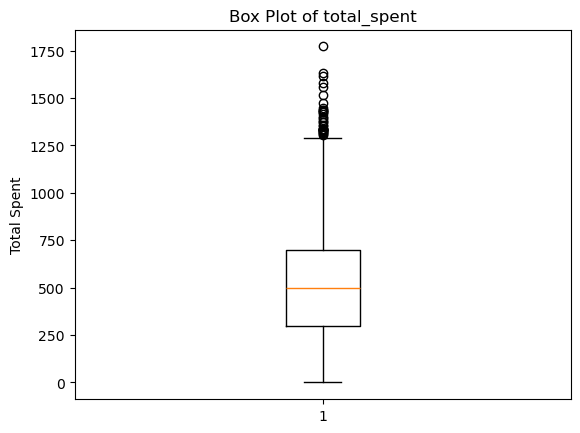

In [56]:
# Create a box plot to visualize distribution and outliers
import matplotlib.pyplot as plt

plt.figure()
plt.boxplot(df['total_spent'])
plt.title("Box Plot of total_spent")
plt.ylabel("Total Spent")
plt.show()

## Outlier Handling

Instead of removing outliers, we cap them:
- Values above upper limit - replaced with upper limit
- Values below lower limit - replaced with lower limit

This preserves data size but controls extreme values.

In [60]:
## basic useage of np.where(condition{boolean array --> can be numpy array of booleans or boolean pandas Series}, value_if_true, value_if_false)

a = np.array([1, 2, 3, 4, 5])
b = np.array([10, 20, 30, 40, 50])

c = np.where(a > 3, b, a) ## This line uses the np.where() function to create a new array c based on a condition applied to array a. The condition checks if each element in a is greater than 3. If the condition is true for an element, the corresponding element from array b is used; otherwise, the original element from array a is retained.

c2 = np.where(a>b, a, b) ## This line uses the np.where() function to create a new array c2 based on a condition applied to array a. The condition checks if each element in a is greater than the corresponding element in b. If the condition is true for an element, the original element from array a is retained; otherwise, the corresponding element from array b is used.
print("Array c:", c)
print("Array c2:", c2)

Array c: [ 1  2  3 40 50]
Array c2: [10 20 30 40 50]


In [61]:
# Create a copy of dataframe for capping
df_capped = df.copy()

# Apply capping using IQR bounds
df_capped['total_spent'] = np.where(
    df_capped['total_spent'] > upper_bound,
    upper_bound,
    df_capped['total_spent']
)

df_capped['total_spent'] = np.where(
    df_capped['total_spent'] < lower_bound,
    lower_bound,
    df_capped['total_spent']
)

print("Outliers capped successfully!")

Outliers capped successfully!


We visualize boxplots:
- Before capping
- After capping

This helps confirm outliers were handled.

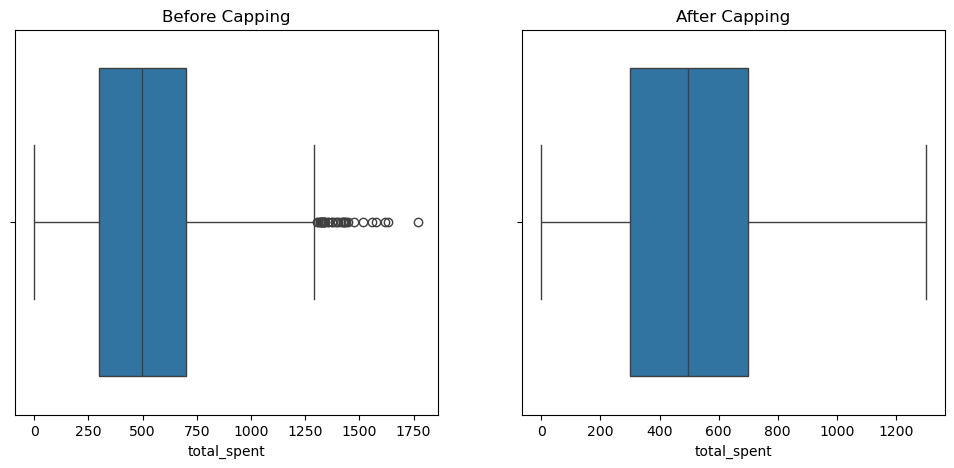

In [68]:
# Plot before vs after boxplots
import seaborn as sns

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.boxplot(x=df['total_spent'])
plt.title("Before Capping")

plt.subplot(1,2,2)
sns.boxplot(x=df_capped['total_spent'])
plt.title("After Capping")

plt.show()

## Imputation

For below tasks, try using `Pipeline` and `ColumnTransformer`. Use the below rule for imputing null values:

* `postal_code`: Imputing with mode (most common postal code)
* `preferred_category` : Impute with mode (most common category)
* `campaign_response` : Create a new category as 'missing_response'.
* `subscription_type` : Impute with mode (most common category)
* `avg_session_duration`: Impute with median
* `payment_method`: Impute with mode (most common category)
* `country`: Impute with mode (most common category)
* `gender`: Impute with mode (most common category)
* `purchase_count`: Impute with 0
* `age`: Impute with median

In [69]:
from sklearn.impute import SimpleImputer

*most_freq* : postal_code, preferred_category, subscription_type, payment_method, country, gender

*median* : avg_session_duration, age

*const* : purchase_count, campaign_response



In [70]:
from sklearn.compose import ColumnTransformer

## Column Transformer
ColumnTransformer allows different preprocessing steps to be applied to different columns within the same pipeline.

Instead of manually handling each column, you define transformations as tuples:

`(name, transformer, columns)`

It then:

Applies each transformer to its specified columns.

Combines the transformed results.

Passes through remaining columns if specified.

## Key Parameters Used Here
1. remainder='passthrough'

    Columns not listed in any transformer are kept unchanged.

    If this were set to 'drop', those columns would be removed.

2. verbose_feature_names_out=False

    Prevents automatic renaming of columns like:

    mode_imputer__gender

    Instead, original column names are preserved.

3. set_output(transform='pandas')

    By default, Scikit Learn returns NumPy arrays.

* This setting ensures that:

    Output remains a Pandas DataFrame

    Column names are preserved

    Downstream processing becomes easier

In [71]:
# Create a list of transformation tuples named impute_tf
# Each tuple contains three elements
# First element is a name for the transformer
# Second element is the imputation strategy object
# Third element is the list of columns to which that strategy should be applied

impute_tf = [

    # Mode imputation
    # SimpleImputer with strategy='most_frequent' replaces missing values
    # with the most frequently occurring value in each specified column
    # This is commonly used for categorical features
    ('mode_imputer',
     SimpleImputer(strategy='most_frequent'),
     ['postal_code', 'preferred_category', 'subscription_type',
      'payment_method', 'country', 'gender']),

    # Median imputation
    # SimpleImputer with strategy='median' replaces missing values
    # with the median of the column
    # This is commonly used for numerical features to reduce impact of outliers
    ('median_imputer',
     SimpleImputer(strategy='median'),
     ['avg_session_duration', 'age']),

    # Constant string imputation
    # Missing values in campaign_response will be replaced
    # with the fixed string 'missing_response'
    ('cp_imputer',
     SimpleImputer(strategy='constant', fill_value='missing_response'),
     ['campaign_response']),

    # Constant numeric imputation
    # Missing values in purchase_count will be replaced with 0
    ('pc_imputer',
     SimpleImputer(strategy='constant', fill_value=0),
     ['purchase_count'])
]

# Create a ColumnTransformer object named impute_ct
# ColumnTransformer allows applying different preprocessing steps
# to different subsets of columns

impute_ct = ColumnTransformer(
    transformers=impute_tf,

    # remainder='passthrough' keeps all columns that are not explicitly listed
    # in impute_tf without modification
    remainder='passthrough',

    # verbose_feature_names_out=False keeps original column names
    # instead of prefixing them with transformer names
    verbose_feature_names_out=False
)

# set_output(transform='pandas') ensures that the output of the transformer
# will be returned as a pandas DataFrame instead of a NumPy array
impute_ct = impute_ct.set_output(transform='pandas')

# Display the ColumnTransformer object
# This shows the configuration of the preprocessing pipeline
impute_ct

ColumnTransformer(remainder='passthrough',
                  transformers=[('mode_imputer',
                                 SimpleImputer(strategy='most_frequent'),
                                 ['postal_code', 'preferred_category',
                                  'subscription_type', 'payment_method',
                                  'country', 'gender']),
                                ('median_imputer',
                                 SimpleImputer(strategy='median'),
                                 ['avg_session_duration', 'age']),
                                ('cp_imputer',
                                 SimpleImputer(fill_value='missing_response',
                                               strategy='constant'),
                                 ['campaign_response']),
                                ('pc_imputer',
                                 SimpleImputer(fill_value=0,
                                               strategy='constant'),
                                 ['purchase_count'])],
                  verbose_feature_names_out=False)

In [72]:
imputed_df = impute_ct.fit_transform(df)

In [73]:
imputed_df.head()

,postal_code,preferred_category,subscription_type,payment_method,country,gender,avg_session_duration,age,campaign_response,purchase_count,...,name,email,join_date,last_purchase,total_spent,city,credit_score,is_active,device_type,z_score
0,06803,Groceries,Corporate,PayPal,Germany,F,1066.626690,41.0,missing_response,51.0,...,Sean Nelson,tylersmith@example.org,"Dec 19, 2020",2025-04-02,238.517142,Port Michaelmouth,663,yes,tablet,-0.920765
1,64245,Clothing,Premium,PayPal,USA,F,327.762945,38.0,no,31.0,...,Eddie Wood,xreed@example.net,30/10/2021,2024-12-25,93.126377,Brig...,656,no,mobile,-1.427088
2,43574,Clothing,Trial,Cryptocurrency,Germany,M,95.654242,11.0,no,87.0,...,Abigail Graham,cartersara@example.com,"May 03, 2022",2025-05-10,873.017713,Port Kevinton,672,no,mobile,1.288885
3,AB-123,Home,Trial,PayPal,India,M,498.371991,40.0,missing_response,0.0,...,Jessica Contreras,fsalazar@example.org,"Aug 03, 2021",NaN,401.703726,Gillespietown,614,yes,mobile,-0.352467
4,82358,Groceries,Premium,Bank Transfer,Germany,F,593.066471,20.0,yes,34.0,...,Kelly Olson,robert21@example.org,"Apr 05, 2024",2025-05-07,1198.186419,jamesberg,692,no,mobile,2.421286


In [80]:
imputed_df['postal_code'].isna().sum()

0

## Scaling and encoding:

For below tasks, try using `Pipeline`, `FeatureUnion` and `ColumnTransformer`. After encoding all categorical variables, scale the encoded ones with `StandardScaler`.


Use the below rule for encoding categorical features:

* Remove `customer_id`, `email`, `name`, `city` and `postal_code` columns.
* One Hot Encode `country`, `subscription_type`, `payment_method`, `preferred_category`, `device_type`
* Ordinal Encode: `gender`, `is_active`, `campaign_response`


Use the below rule for scaling numerical features:

* `StandardScaler`: `age`, '`total_spent`, `avg_session_duration`
* `MinMaxScaler` : `purchase_count`
* `RobustScaler` : `credit_score`

In [81]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler

In [82]:
df = df.drop(['customer_id', 'email', 'name', 'city', 'postal_code'], axis=1)

## Step: Encoding Categorical Features using ColumnTransformer

In this step, we are converting categorical columns into numerical format so that they can be used in machine learning models.

Most ML algorithms cannot understand text (categorical data), so we must encode them into numbers.

We are using two types of encoding here:

### 1. One-Hot Encoding (OHE)

Used for nominal categorical data (no order or ranking).

Columns encoded using OneHotEncoder:
- country
- subscription_type
- payment_method
- preferred_category
- device_type

How One-Hot Encoding works:
Each unique category becomes a new column with values 0 or 1.

Example:
country column:
India, USA, UK

After encoding:
country_India | country_USA | country_UK  
1             | 0           | 0

Advantages:
- No ranking is introduced
- Model treats categories independently

We use `sparse_output=False` so that output is returned as a normal dataframe instead of sparse matrix.

### 2. Ordinal Encoding (OE)

Used for categorical columns where values can be represented as ordered numbers.

Columns encoded using OrdinalEncoder:
- gender
- is_active
- campaign_response

OrdinalEncoder converts categories into numeric labels:
Example:
Yes = 1  
No = 0  

It assigns integer values to each category.

### 3. ColumnTransformer

ColumnTransformer allows us to:
- Apply different transformations to different columns
- Combine them into one pipeline
- Keep preprocessing structured and reusable

Parameters used:
- transformers - list of encoding steps
- remainder='drop' - drops columns not specified
- verbose_feature_names_out=False - keeps column names clean
- set_output(transform='pandas') - ensures output is a pandas dataframe

This preprocessing step is important before training ML models
because models require numerical input.

In [83]:
# Import necessary preprocessing tools
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

# We create a list of transformations to apply on different columns

encode_tf = [

    # One-Hot Encoding for nominal categorical columns
    # sparse_output=False ensures output is a dense array (not sparse matrix)
    ('ohe', OneHotEncoder(sparse_output=False),
     ['country', 'subscription_type', 'payment_method',
      'preferred_category', 'device_type']),

    # Ordinal Encoding for binary/ordered categorical columns
    # Converts categories into numeric labels (0,1,2...)
    ('oe', OrdinalEncoder(),
     ['gender', 'is_active', 'campaign_response'])
]

# ColumnTransformer applies different transformations
# to different columns in a structured pipeline

encode_ct = ColumnTransformer(
    transformers=encode_tf,             # transformation list defined above
    remainder='drop',                   # drop columns not mentioned here
    verbose_feature_names_out=False     # keeps output column names clean
)


# By default sklearn returns numpy array
# We convert output to pandas for easier analysis

encode_ct = encode_ct.set_output(transform='pandas')

# Shows structure of transformations defined
encode_ct

ColumnTransformer(transformers=[('ohe', OneHotEncoder(sparse_output=False),
                                 ['country', 'subscription_type',
                                  'payment_method', 'preferred_category',
                                  'device_type']),
                                ('oe', OrdinalEncoder(),
                                 ['gender', 'is_active', 'campaign_response'])],
                  verbose_feature_names_out=False)

## Creating a Preprocessing Pipeline with Encoding and Scaling

In this cell, we are building a preprocessing pipeline that performs two major operations sequentially:

1. Encoding categorical variables
2. Scaling numerical features

This ensures that all preprocessing steps are organized in a single reusable object.

Why use a Pipeline?

A Pipeline allows us to chain multiple preprocessing steps together so that:
- Transformations are applied in the correct order
- Code becomes clean and modular
- The same preprocessing can be reused during training and testing
- Data leakage is prevented in machine learning workflows

In [85]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create a preprocessing pipeline
# The pipeline applies encoding first, then scaling
pipe1 = Pipeline(
    steps=[
        # First apply the previously defined ColumnTransformer
        # This converts categorical variables into numerical format
        ('encoding', encode_ct),

        # After encoding, apply StandardScaler
        # This standardizes all features to have mean = 0 and std = 1
        ('scaling', StandardScaler())
    ]
)

# Ensure that the transformed output is returned as a pandas DataFrame
# This keeps column names instead of returning a NumPy array
pipe1 = pipe1.set_output(transform='pandas')

# Display the pipeline structure
# This shows the sequence of transformations defined
pipe1

Pipeline(steps=[('encoding',
                 ColumnTransformer(transformers=[('ohe',
                                                  OneHotEncoder(sparse_output=False),
                                                  ['country',
                                                   'subscription_type',
                                                   'payment_method',
                                                   'preferred_category',
                                                   'device_type']),
                                                 ('oe', OrdinalEncoder(),
                                                  ['gender', 'is_active',
                                                   'campaign_response'])],
                                   verbose_feature_names_out=False)),
                ('scaling', StandardScaler())])

In [88]:
scale_tf = [('SS', StandardScaler(), ['age', 'total_spent', 'avg_session_duration']),

            ('MinMax', MinMaxScaler(), ['purchase_count']),

            ('Robust', RobustScaler(), ['credit_score'])]

scale_ct = ColumnTransformer(transformers=scale_tf, remainder='drop', verbose_feature_names_out=False).set_output(transform='pandas')

scale_ct

ColumnTransformer(transformers=[('SS', StandardScaler(),
                                 ['age', 'total_spent',
                                  'avg_session_duration']),
                                ('MinMax', MinMaxScaler(), ['purchase_count']),
                                ('Robust', RobustScaler(), ['credit_score'])],
                  verbose_feature_names_out=False)

In [89]:
pipe2 = Pipeline(steps=[('scaling', scale_ct)]).set_output(transform='pandas')

pipe2

Pipeline(steps=[('scaling',
                 ColumnTransformer(transformers=[('SS', StandardScaler(),
                                                  ['age', 'total_spent',
                                                   'avg_session_duration']),
                                                 ('MinMax', MinMaxScaler(),
                                                  ['purchase_count']),
                                                 ('Robust', RobustScaler(),
                                                  ['credit_score'])],
                                   verbose_feature_names_out=False))])

In [90]:
pipe1.fit_transform(df)

,country_Australia,country_Brazil,country_Canada,country_China,country_France,country_Germany,country_India,country_Japan,country_UK,country_USA,...,preferred_category_Electronics,preferred_category_Groceries,preferred_category_Home,preferred_category_nan,device_type_desktop,device_type_mobile,device_type_tablet,gender,is_active,campaign_response
0,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,3.264202,-0.306354,-0.297082,-0.301643,-0.298674,...,-0.428617,2.255311,-0.427472,-0.519462,-0.827256,-0.809032,2.011953,-1.009090,0.984914,NaN
1,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,-0.301643,3.348136,...,-0.428617,-0.443398,-0.427472,-0.519462,-0.827256,1.236044,-0.497029,-1.009090,-1.015317,-0.999501
2,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,3.264202,-0.306354,-0.297082,-0.301643,-0.298674,...,-0.428617,-0.443398,-0.427472,-0.519462,-0.827256,1.236044,-0.497029,0.990992,-1.015317,-0.999501
3,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,3.264202,-0.297082,-0.301643,-0.298674,...,-0.428617,-0.443398,2.339336,-0.519462,-0.827256,1.236044,-0.497029,NaN,0.984914,NaN
4,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,3.264202,-0.306354,-0.297082,-0.301643,-0.298674,...,-0.428617,2.255311,-0.427472,-0.519462,-0.827256,1.236044,-0.497029,-1.009090,-1.015317,1.000500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,3.315178,-0.298674,...,-0.428617,2.255311,-0.427472,-0.519462,1.208816,-0.809032,-0.497029,-1.009090,0.984914,1.000500
9996,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,-0.301643,-0.298674,...,-0.428617,2.255311,-0.427472,-0.519462,1.208816,-0.809032,-0.497029,-1.009090,0.984914,NaN
9997,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,-0.301643,3.348136,...,-0.428617,2.255311,-0.427472,-0.519462,-0.827256,1.236044,-0.497029,-1.009090,-1.015317,-0.999501
9998,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,3.366074,-0.301643,-0.298674,...,2.333088,-0.443398,-0.427472,-0.519462,-0.827256,-0.809032,2.011953,NaN,-1.015317,1.000500


In [92]:
pipe2.fit_transform(df)

,age,total_spent,avg_session_duration,purchase_count,credit_score
0,-0.250251,-0.920811,1.561425,0.505051,-0.253731
1,-0.452240,-1.427160,-0.923717,0.303030,-0.305970
2,-2.270141,1.288950,-1.704407,0.868687,-0.186567
3,-0.317581,-0.352484,-0.349880,NaN,-0.619403
4,-1.664174,2.421407,NaN,0.333333,-0.037313
...,...,...,...,...,...
9995,-0.317581,0.392581,-1.475811,0.979798,0.231343
9996,0.221057,2.200197,-0.288668,0.969697,0.305970
9997,-0.654229,2.913260,NaN,0.050505,1.141791
9998,0.961683,0.605145,NaN,0.888889,-0.283582


## Combining Multiple Preprocessing Pipelines using FeatureUnion

In this cell, we combine multiple preprocessing pipelines into a single unified transformer using FeatureUnion.

FeatureUnion allows multiple transformers or pipelines to be applied to the same dataset in parallel and then merges their outputs column-wise into one final dataset.


This is different from a Pipeline, where transformations happen sequentially. In FeatureUnion, transformations occur independently and their outputs are concatenated.


**Why FeatureUnion is used here**


We have created two separate preprocessing pipelines:

pipe1

This pipeline performs:
- Encoding of categorical features using ColumnTransformer
- Scaling of the encoded output using StandardScaler

This pipeline mainly handles categorical feature preprocessing and standardization.

pipe2  

This pipeline applies scaling using `scale_ct`.  
The `scale_ct` transformer is a ColumnTransformer that scales selected numerical columns.  
This ensures numerical features are standardized without affecting categorical encoding logic.

Both pipelines operate on the same dataset but perform different transformations.  
FeatureUnion combines their outputs into a single feature set that can be directly used for machine learning.

**How the data flows**

The input dataset is sent to both pipelines simultaneously.
pipe1 returns encoded and scaled categorical features.
pipe2 returns scaled numerical features.
FeatureUnion concatenates both outputs column-wise into one final dataframe.


Output format


We use set_output(transform='pandas') so the final combined output remains a pandas DataFrame with proper column names instead of a NumPy array.


This unified feature engineering block can now be used before training any machine learning model.

In [93]:
from sklearn.pipeline import FeatureUnion

# FeatureUnion combines multiple transformers/pipelines
# It applies them in parallel on the same dataset
# and concatenates their outputs column-wise
fe = FeatureUnion(
    transformer_list=[

        # pipe1 performs:
        # categorical encoding using ColumnTransformer
        # followed by StandardScaler
        ('encode_tf', pipe1),

        # pipe2 performs:
        # scaling of selected numerical columns using scale_ct
        # This ensures numeric features are standardized separately
        ('scale_tf', pipe2)
    ]
)

# Convert output to pandas DataFrame instead of NumPy array
# This keeps column names and makes debugging easier
fe = fe.set_output(transform='pandas')

# Display structure of FeatureUnion
# Shows both pipelines that will run in parallel
fe

FeatureUnion(transformer_list=[('encode_tf',
                                Pipeline(steps=[('encoding',
                                                 ColumnTransformer(transformers=[('ohe',
                                                                                  OneHotEncoder(sparse_output=False),
                                                                                  ['country',
                                                                                   'subscription_type',
                                                                                   'payment_method',
                                                                                   'preferred_category',
                                                                                   'device_type']),
                                                                                 ('oe',
                                                                                  OrdinalEncoder(),
                                                                                  ['gender',
                                                                                   'is_active',
                                                                                   'campaign_response'])],
                                                                   verbose_feature_names_out=False)),
                                                ('scaling',
                                                 StandardScaler())])),
                               ('scale_tf',
                                Pipeline(steps=[('scaling',
                                                 ColumnTransformer(transformers=[('SS',
                                                                                  StandardScaler(),
                                                                                  ['age',
                                                                                   'total_spent',
                                                                                   'avg_session_duration']),
                                                                                 ('MinMax',
                                                                                  MinMaxScaler(),
                                                                                  ['purchase_count']),
                                                                                 ('Robust',
                                                                                  RobustScaler(),
                                                                                  ['credit_score'])],
                                                                   verbose_feature_names_out=False))]))])

In [94]:
fe.fit_transform(df)

,encode_tf__country_Australia,encode_tf__country_Brazil,encode_tf__country_Canada,encode_tf__country_China,encode_tf__country_France,encode_tf__country_Germany,encode_tf__country_India,encode_tf__country_Japan,encode_tf__country_UK,encode_tf__country_USA,...,encode_tf__device_type_mobile,encode_tf__device_type_tablet,encode_tf__gender,encode_tf__is_active,encode_tf__campaign_response,scale_tf__age,scale_tf__total_spent,scale_tf__avg_session_duration,scale_tf__purchase_count,scale_tf__credit_score
0,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,3.264202,-0.306354,-0.297082,-0.301643,-0.298674,...,-0.809032,2.011953,-1.009090,0.984914,NaN,-0.250251,-0.920811,1.561425,0.505051,-0.253731
1,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,-0.301643,3.348136,...,1.236044,-0.497029,-1.009090,-1.015317,-0.999501,-0.452240,-1.427160,-0.923717,0.303030,-0.305970
2,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,3.264202,-0.306354,-0.297082,-0.301643,-0.298674,...,1.236044,-0.497029,0.990992,-1.015317,-0.999501,-2.270141,1.288950,-1.704407,0.868687,-0.186567
3,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,3.264202,-0.297082,-0.301643,-0.298674,...,1.236044,-0.497029,NaN,0.984914,NaN,-0.317581,-0.352484,-0.349880,NaN,-0.619403
4,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,3.264202,-0.306354,-0.297082,-0.301643,-0.298674,...,1.236044,-0.497029,-1.009090,-1.015317,1.000500,-1.664174,2.421407,NaN,0.333333,-0.037313
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,3.315178,-0.298674,...,-0.809032,-0.497029,-1.009090,0.984914,1.000500,-0.317581,0.392581,-1.475811,0.979798,0.231343
9996,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,-0.301643,-0.298674,...,-0.809032,-0.497029,-1.009090,0.984914,NaN,0.221057,2.200197,-0.288668,0.969697,0.305970
9997,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,-0.297082,-0.301643,3.348136,...,1.236044,-0.497029,-1.009090,-1.015317,-0.999501,-0.654229,2.913260,NaN,0.050505,1.141791
9998,-0.309274,-0.298475,-0.300655,-0.306939,-0.309080,-0.306354,-0.306354,3.366074,-0.301643,-0.298674,...,-0.809032,2.011953,NaN,-1.015317,1.000500,0.961683,0.605145,NaN,0.888889,-0.283582


## Difference Between ColumnTransformer, Pipeline, and FeatureUnion

ColumnTransformer, Pipeline, and FeatureUnion are preprocessing tools in scikit-learn used to organize and automate data transformation. Each serves a different purpose in building structured machine learning workflows.

### ColumnTransformer

ColumnTransformer is used when different columns of a dataset need different preprocessing techniques.

It allows us to apply specific transformations to specific columns and then combine the results into one dataset.

Example uses:
- One-hot encode categorical columns
- Scale numerical columns
- Apply different preprocessing to different feature groups

Pros:
- Handles column-wise transformations efficiently
- Keeps preprocessing structured and readable
- Essential for mixed data (categorical + numerical)
- Prevents manual column handling errors

Cons:
- Can become complex with many column groups
- Only handles column-based transformations, not full workflows

### Pipeline

Pipeline is used to apply transformations sequentially.  
The output of one step becomes the input of the next.

It is helpful when preprocessing must follow a fixed order, such as:
Encoding -> Scaling -> Feature Selection -> Model

Pros:
- Ensures transformations happen in correct order
- Prevents data leakage during training/testing
- Makes workflow reusable and clean
- Easy to integrate with model training

Cons:
- Steps must be sequential
- Cannot run transformations in parallel
- Less flexible for complex feature engineering

### FeatureUnion

FeatureUnion is used to apply multiple transformers or pipelines in parallel to the same dataset and then combine their outputs.

Each transformer works independently and their outputs are concatenated into a single dataset.

Pros:
- Allows parallel feature engineering
- Useful for combining different feature sets
- Helps create richer feature representations
- Works well with multiple pipelines

Cons:
- Can increase feature size significantly
- Harder to debug if many transformers exist
- Requires careful column management to avoid duplication

### Which is More Preferred?

All three serve different purposes and are often used together rather than as replacements.

**Most commonly preferred structure in real projects:**

**ColumnTransformer inside Pipeline**
**This is the most standard and recommended approach for structured preprocessing.**

FeatureUnion is preferred when:
- You want multiple feature engineering pipelines running in parallel
- You want to combine different feature representations

**General guideline:**
- Use ColumnTransformer for column-wise transformations
- Use Pipeline for sequential workflows
- Use FeatureUnion for parallel feature engineering

In most real-world machine learning pipelines, Pipeline with ColumnTransformer is the most commonly used and preferred setup, while FeatureUnion is used in more advanced feature engineering scenarios.